# Train lần 1: MobileNetV2 PCB trên Colab

Notebook tự tải Kaggle, tạo và kiểm tra patch, train embedding 32D, xem kết quả validation rồi lưu checkpoint lên Drive.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
from pathlib import Path
import os, sys, shutil, subprocess, zipfile
PROJECT_ROOT = Path('/content/pcb_project')
PROJECT_ROOT.mkdir(parents=True, exist_ok=True)
PACKAGE_DIR = Path('/content/pcb_pipeline')
PACKAGE_DIR.mkdir(parents=True, exist_ok=True)
RAW_DIR = Path('/content/raw_data/kaggle_pcb')
FINAL_DRIVE_DIR = Path('/content/drive/MyDrive/pcb_model_final')
print('Temporary project:', PROJECT_ROOT)
print('Only final deployment files will be copied to:', FINAL_DRIVE_DIR)


Mounted at /content/drive
Temporary project: /content/pcb_project
Only final deployment files will be copied to: /content/drive/MyDrive/pcb_model_final


In [ ]:
%pip -q install kaggle 'opencv-python-headless>=4.8,<4.12' 'scikit-learn>=1.4' 'Pillow>=10'
import tensorflow as tf
for gpu in tf.config.list_physical_devices('GPU'):
    try: tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError: pass
print('TensorFlow:', tf.__version__, '| GPU:', tf.config.list_physical_devices('GPU'))


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.0/50.0 MB 25.3 MB/s eta 0:00:00
TensorFlow: 2.21.0 | GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## Chuẩn bị mã pipeline
Mã nguồn được chia thành các phần có tiêu đề để dễ xem. Chạy **theo thứ tự** các cell `%%writefile`; các phần sau dùng `-a` để nối vào cùng file trong `/content`.

### `__init__.py` · phần 1/1: mã nguồn
Chạy cell kế tiếp để ghi phần mã này vào `/content/pcb_pipeline/__init__.py`.

In [ ]:
%%writefile /content/pcb_pipeline/__init__.py
"""PCB embedding and anomaly detection pipeline."""


Writing /content/pcb_pipeline/__init__.py


### `data.py` · phần 1/3: kiểm tra nguồn và chia board
Chạy cell kế tiếp để ghi phần mã này vào `/content/pcb_pipeline/data.py`.

In [ ]:
%%writefile /content/pcb_pipeline/data.py
"""Source validation and leakage-safe PCB patch preparation."""

from __future__ import annotations

import csv
import hashlib
import json
import re
from collections import Counter, defaultdict
from pathlib import Path
from xml.etree import ElementTree as ET

import cv2
import numpy as np


CLASS_NAMES = (
    "normal", "open_circuit", "short", "mouse_bite", "spur",
    "spurious_copper", "missing_hole",
)
LABELS = {name: i for i, name in enumerate(CLASS_NAMES)}
XML_NAMES = {
    "open circuit": "open_circuit", "open": "open_circuit",
    "short": "short", "short circuit": "short",
    "mouse bite": "mouse_bite", "mousebite": "mouse_bite",
    "spur": "spur", "spurious copper": "spurious_copper",
    "missing hole": "missing_hole", "missinghole": "missing_hole",
}
SOURCE_FIELDS = ("image_path", "xml_path", "board_id", "domain", "session_id", "split", "is_defect")
PATCH_FIELDS = ("path", "label", "class_name", "split", "domain", "board_id", "session_id", "image_id", "defect_id")
PATCH_QA_FIELDS = ("source_image_path", "crop_x1", "crop_y1", "crop_x2", "crop_y2", "bbox_coverage", "is_jittered")


def _resolve(base: Path, value: str) -> str:
    if not value:
        return ""
    p = Path(value)
    return str((p if p.is_absolute() else base / p).resolve())


def read_sources(csv_path: str | Path) -> list[dict[str, str]]:
    csv_path = Path(csv_path).resolve()
    with csv_path.open(newline="", encoding="utf-8-sig") as f:
        reader = csv.DictReader(f)
        missing = set(SOURCE_FIELDS) - set(reader.fieldnames or ())
        if missing:
            raise ValueError(f"Missing source CSV columns: {sorted(missing)}")
        rows = [{k: (v or "").strip() for k, v in row.items()} for row in reader]
    if not rows:
        raise ValueError("Source CSV is empty")
    seen_images: set[str] = set()
    group_split: dict[tuple[str, str], str] = {}
    for row in rows:
        row["image_path"] = _resolve(csv_path.parent, row["image_path"])
        row["xml_path"] = _resolve(csv_path.parent, row["xml_path"])
        if not Path(row["image_path"]).is_file():
            raise FileNotFoundError(row["image_path"])
        if row["xml_path"] and not Path(row["xml_path"]).is_file():
            raise FileNotFoundError(row["xml_path"])
        if not row["board_id"] or not row["domain"] or not row["session_id"]:
            raise ValueError(f"board_id/domain/session_id required: {row['image_path']}")
        if row["split"] not in {"train", "val", "test"}:
            raise ValueError(f"Invalid split for {row['image_path']}: {row['split']}")
        if row["is_defect"] not in {"0", "1"}:
            raise ValueError(f"is_defect must be 0/1: {row['image_path']}")
        if row["image_path"] in seen_images:
            raise ValueError(f"Duplicate image: {row['image_path']}")
        seen_images.add(row["image_path"])
        group = (row["domain"], row["board_id"])
        old = group_split.setdefault(group, row["split"])
        if old != row["split"]:
            raise ValueError(f"Board leaked across splits: {group}: {old}/{row['split']}")
        boxes = read_boxes(row["xml_path"])
        if bool(boxes) != (row["is_defect"] == "1"):
            raise ValueError(f"is_defect and XML objects disagree: {row['image_path']}")
    if not any(r["split"] == "train" for r in rows):
        raise ValueError("No train images")
    if not any(r["split"] == "val" for r in rows):
        raise ValueError("No val images")
    if not any(r["split"] == "test" for r in rows):
        raise ValueError("No test images")
    return rows


def create_kaggle_sources(dataset_dir: str | Path, output_csv: str | Path,
                          seed: int = 42) -> dict[str, int]:
    """Index HRIPCB Kaggle folders, include PCB_USED templates, and split by board prefix."""
    dataset_dir = Path(dataset_dir).resolve()
    output_csv = Path(output_csv).resolve()
    roots = [dataset_dir] + [p for p in dataset_dir.rglob("*") if p.is_dir()]
    dataset_root = next((p for p in roots if p.name.casefold() == "pcb_dataset"), None)
    if dataset_root is None:
        raise FileNotFoundError(f"Could not find PCB_DATASET below {dataset_dir}")
    children = {p.name.casefold(): p for p in dataset_root.iterdir() if p.is_dir()}
    image_root = children.get("images") or children.get("images(defective)")
    annotation_root = children.get("annotations")
    normal_root = children.get("pcb_used") or children.get("pcb_used(defect-free)")
    if image_root is None or annotation_root is None or normal_root is None:
        raise FileNotFoundError("Expected images/, Annotations/, and PCB_USED/ inside PCB_DATASET")

    xml_by_stem: dict[str, list[Path]] = defaultdict(list)
    for path in annotation_root.rglob("*.xml"):
        xml_by_stem[path.stem.casefold()].append(path)

    rows: list[dict[str, str]] = []
    seen_images: set[str] = set()
    for image_path in sorted(p for p in image_root.rglob("*") if p.suffix.casefold() in {".jpg", ".jpeg", ".png"}):
        match = re.match(r"^(\d+)(?:[_-]|$)", image_path.stem)
        if not match:
            raise ValueError(f"Cannot infer board ID from Kaggle filename: {image_path.name}")
        relative = image_path.relative_to(image_root)
        xml_path = annotation_root / relative.parent / f"{image_path.stem}.xml"
        if not xml_path.is_file():
            options = xml_by_stem.get(image_path.stem.casefold(), [])
            if len(options) != 1:
                raise FileNotFoundError(f"Expected one matching XML for {image_path}; found {len(options)}")
            xml_path = options[0]
        read_boxes(str(xml_path))  # Fail early on unknown or malformed labels.
        rows.append({"image_path": str(image_path), "xml_path": str(xml_path),
                     "board_id": match.group(1), "domain": "kaggle", "session_id": "source",
                     "split": "", "is_defect": "1"})
        seen_images.add(str(image_path.resolve()))

    for image_path in sorted(p for p in normal_root.rglob("*") if p.suffix.casefold() in {".jpg", ".jpeg", ".png"}):
        match = re.match(r"^(\d+)(?:[_-]|$)", image_path.stem)
        if not match:
            raise ValueError(f"Cannot infer board ID from template filename: {image_path.name}")
        rows.append({"image_path": str(image_path.resolve()), "xml_path": "",
                     "board_id": match.group(1), "domain": "kaggle", "session_id": "template",
                     "split": "", "is_defect": "0"})

    labels_by_board: dict[str, Counter] = defaultdict(Counter)
    for row in rows:
        labels = ["normal"] if row["is_defect"] == "0" else [name for name, _ in read_boxes(row["xml_path"])]
        labels_by_board[row["board_id"]].update(labels)
    boards = sorted(labels_by_board)
    if len(boards) < 3:
        raise ValueError(f"Need at least 3 board IDs for group train/val/test split; found {boards}")

    rng = np.random.default_rng(seed)
    targets = {"train": 0.70, "val": 0.15, "test": 0.15}
    all_classes = set(CLASS_NAMES)
    best = None
    for _ in range(5000):
        shuffled = list(np.asarray(boards)[rng.permutation(len(boards))])
        n_train = max(1, round(0.70 * len(boards)))
        n_val = max(1, round(0.15 * len(boards)))
        if n_train + n_val >= len(boards):
            n_train = len(boards) - 2
            n_val = 1
        groups = {"train": set(shuffled[:n_train]), "val": set(shuffled[n_train:n_train + n_val]),
                  "test": set(shuffled[n_train + n_val:])}
        class_counts = {split: Counter() for split in targets}
        for split, group_ids in groups.items():
            for board in group_ids:
                class_counts[split].update(labels_by_board[board])
        if not all_classes.issubset(class_counts["train"]):
            continue
        if any(class_counts[s]["normal"] == 0 or sum(class_counts[s][c] for c in CLASS_NAMES[1:]) == 0
               for s in ("val", "test")):
            continue
        score = 0.0
        for split, target in targets.items():
            for name in CLASS_NAMES:
                total = sum(class_counts[s][name] for s in targets)
                if total:
                    score += abs(class_counts[split][name] / total - target)
            score += abs(len(groups[split]) / len(boards) - target)
        if best is None or score < best[0]:
            best = (score, groups, class_counts)
    if best is None:
        raise ValueError("Could not form group split with all 6 defects in train and normal/defect in val/test")

    _, groups, class_counts = best
    board_split = {board: split for split, group_ids in groups.items() for board in group_ids}
    for row in rows:
        row["split"] = board_split[row["board_id"]]
    output_csv.parent.mkdir(parents=True, exist_ok=True)
    with output_csv.open("w", newline="", encoding="utf-8") as f:
        writer = csv.DictWriter(f, fieldnames=SOURCE_FIELDS)
        writer.writeheader()
        writer.writerows(rows)
    summary = {split: sum(class_counts[split].values()) for split in targets}
    print("Auto-created sources.csv with board-level split:",
          {split: {name: class_counts[split][name] for name in CLASS_NAMES if class_counts[split][name]}
           for split in targets})
    return summary




Writing /content/pcb_pipeline/data.py


### `data.py` · phần 2/3: cắt patch và tạo ảnh QA
Chạy cell kế tiếp để ghi phần mã này vào `/content/pcb_pipeline/data.py`.

In [ ]:
%%writefile -a /content/pcb_pipeline/data.py
def read_boxes(xml_path: str) -> list[tuple[str, tuple[int, int, int, int]]]:
    if not xml_path:
        return []
    root = ET.parse(xml_path).getroot()
    boxes = []
    for obj in root.findall("object"):
        raw = " ".join((obj.findtext("name") or "").lower().replace("_", " ").replace("-", " ").split())
        name = XML_NAMES.get(raw)
        if name is None:
            raise ValueError(f"Unknown XML class {raw!r} in {xml_path}")
        box = obj.find("bndbox")
        if box is None:
            raise ValueError(f"Missing bndbox in {xml_path}")
        coords = tuple(int(float(box.findtext(k, "nan"))) for k in ("xmin", "ymin", "xmax", "ymax"))
        if coords[2] <= coords[0] or coords[3] <= coords[1]:
            raise ValueError(f"Invalid box {coords} in {xml_path}")
        boxes.append((name, coords))
    return boxes


def crop_bounds(cx: float, cy: float, side: float) -> tuple[int, int, int, int]:
    half = max(1, round(side / 2))
    x1, y1 = round(cx) - half, round(cy) - half
    x2, y2 = x1 + 2 * half, y1 + 2 * half
    return x1, y1, x2, y2


def box_coverage(box: tuple[int, int, int, int], crop: tuple[int, int, int, int]) -> float:
    bx1, by1, bx2, by2 = box
    x1, y1, x2, y2 = crop
    intersection = max(0, min(bx2, x2) - max(bx1, x1)) * max(0, min(by2, y2) - max(by1, y1))
    return intersection / ((bx2 - bx1) * (by2 - by1))


def crop_center(image: np.ndarray, cx: float, cy: float, side: float, out_size: int) -> np.ndarray:
    x1, y1, x2, y2 = crop_bounds(cx, cy, side)
    h, w = image.shape[:2]
    part = image[max(0, y1):min(h, y2), max(0, x1):min(w, x2)]
    if part.size == 0:
        raise ValueError("Crop falls outside image")
    part = cv2.copyMakeBorder(
        part, max(0, -y1), max(0, y2 - h), max(0, -x1), max(0, x2 - w),
        cv2.BORDER_REFLECT_101,
    )
    interpolation = cv2.INTER_AREA if part.shape[0] > out_size else cv2.INTER_LINEAR
    return cv2.resize(part, (out_size, out_size), interpolation=interpolation)


def normal_centers(image: np.ndarray, size: int, count: int, rng: np.random.Generator) -> list[tuple[int, int]]:
    h, w = image.shape[:2]
    stride = max(1, size // 2)
    xs = list(range(size // 2, max(size // 2 + 1, w), stride))
    ys = list(range(size // 2, max(size // 2 + 1, h), stride))
    centers = [(min(x, w - 1), min(y, h - 1)) for y in ys for x in xs]
    if not centers:
        return []
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    edges = cv2.Canny(gray, 80, 160)
    scores = []
    for x, y in centers:
        y1, y2 = max(0, y - size // 2), min(h, y + size // 2)
        x1, x2 = max(0, x - size // 2), min(w, x + size // 2)
        scores.append(float(edges[y1:y2, x1:x2].mean()))
    uniform_n = min(len(centers), count // 2)
    chosen = set(int(i) for i in rng.choice(len(centers), uniform_n, replace=False))
    for i in np.argsort(scores)[::-1]:
        if len(chosen) >= min(count, len(centers)):
            break
        chosen.add(int(i))
    return [centers[i] for i in sorted(chosen)]


def write_qa_sheets(rows: list[dict[str, str]], out_dir: Path, seed: int) -> None:
    """Small, reproducible visual sample for each split/class."""
    by_group: dict[tuple[str, str], list[dict[str, str]]] = defaultdict(list)
    for row in rows:
        by_group[(row["split"], row["class_name"])].append(row)
    out_dir.mkdir(parents=True, exist_ok=True)
    rng = np.random.default_rng(seed)
    for (split, name), group in sorted(by_group.items()):
        # Always show a low-coverage crop and a jittered crop when available.
        chosen = [min(group, key=lambda r: float(r["bbox_coverage"]) if r["bbox_coverage"] else 1.0)]
        jittered = next((r for r in group if r["is_jittered"] == "1"), None)
        if jittered is not None and jittered not in chosen:
            chosen.append(jittered)
        remaining = [r for r in group if r not in chosen]
        if remaining:
            ids = rng.choice(len(remaining), min(16 - len(chosen), len(remaining)), replace=False)
            chosen.extend(remaining[int(i)] for i in ids)
        thumbs = []
        for row in chosen:
            patch = cv2.imread(row["path"], cv2.IMREAD_COLOR)
            if patch is None:
                raise ValueError(f"Cannot read QA patch: {row['path']}")
            thumb = cv2.resize(patch, (128, 128), interpolation=cv2.INTER_NEAREST)
            label = "jitter" if row["is_jittered"] == "1" else "center/normal"
            cv2.putText(thumb, label, (3, 121), cv2.FONT_HERSHEY_SIMPLEX, 0.32, (255, 255, 255), 1)
            thumbs.append(thumb)
        blank = np.zeros((128, 128, 3), dtype=np.uint8)
        thumbs.extend([blank] * (16 - len(thumbs)))
        sheet = np.vstack([np.hstack(thumbs[i:i + 4]) for i in range(0, 16, 4)])
        target = out_dir / f"{split}_{name}.jpg"
        if not cv2.imwrite(str(target), sheet):
            raise IOError(f"Could not save QA sheet: {target}")




Appending to /content/pcb_pipeline/data.py


### `data.py` · phần 3/3: tạo manifest patch
Chạy cell kế tiếp để ghi phần mã này vào `/content/pcb_pipeline/data.py`.

In [ ]:
%%writefile -a /content/pcb_pipeline/data.py
def prepare(sources_csv: str, out_dir: str, size: int = 64, train_copies: int = 3,
            normal_per_image: int = 12, seed: int = 42) -> None:
    if size < 32 or train_copies < 1 or normal_per_image < 1:
        raise ValueError("size >= 32, train_copies >= 1, normal_per_image >= 1 required")
    sources = read_sources(sources_csv)
    output = Path(out_dir).resolve()
    patch_dir = output / "patches"
    patch_dir.mkdir(parents=True, exist_ok=True)
    rng = np.random.default_rng(seed)
    output.mkdir(parents=True, exist_ok=True)
    counts: dict[str, Counter] = {split: Counter() for split in ("train", "val", "test")}
    qa_rows: list[dict[str, str]] = []
    with (output / "patches.csv").open("w", newline="", encoding="utf-8") as f:
        writer = csv.DictWriter(f, fieldnames=PATCH_FIELDS + PATCH_QA_FIELDS)
        writer.writeheader()
        for source in sources:
            image = cv2.imread(source["image_path"], cv2.IMREAD_COLOR)
            if image is None:
                raise ValueError(f"Cannot decode {source['image_path']}")
            image_id = hashlib.sha256(source["image_path"].encode()).hexdigest()[:16]
            boxes = read_boxes(source["xml_path"])
            items: list[tuple[str, int, np.ndarray, tuple[int, int, int, int], float, bool]] = []
            for defect_id, (name, (x1, y1, x2, y2)) in enumerate(boxes):
                copies = train_copies if source["split"] == "train" else 1
                for copy_id in range(copies):
                    jitter = copy_id > 0
                    box = (x1, y1, x2, y2)
                    for attempt in range(40):
                        shift = 0.2 * (1 - attempt / 40)
                        cx = (x1 + x2) / 2 + (rng.uniform(-shift, shift) * size if jitter else 0)
                        cy = (y1 + y2) / 2 + (rng.uniform(-shift, shift) * size if jitter else 0)
                        scale = rng.uniform(0.9, 1.15) if jitter else 1.0
                        side = max(size * scale, 1.3 * max(x2 - x1, y2 - y1))
                        bounds = crop_bounds(cx, cy, side)
                        coverage = box_coverage(box, bounds)
                        if coverage >= 0.8 and bounds[0] <= (x1 + x2) / 2 < bounds[2] and bounds[1] <= (y1 + y2) / 2 < bounds[3]:
                            break
                    else:
                        raise ValueError(f"Could not keep >=80% of defect box: {source['image_path']} box={box}")
                    items.append((name, defect_id, crop_center(image, cx, cy, side, size), bounds, coverage, jitter))
            if not boxes:  # Only verified clean images supply normal patches.
                for normal_id, (cx, cy) in enumerate(normal_centers(image, size, normal_per_image, rng)):
                    items.append(("normal", normal_id, crop_center(image, cx, cy, size, size),
                                  crop_bounds(cx, cy, size), 0.0, False))
            for item_id, (name, defect_id, patch, bounds, coverage, jitter) in enumerate(items):
                filename = f"{source['split']}_{image_id}_{item_id:04d}.png"
                path = patch_dir / filename
                if not cv2.imwrite(str(path), patch):
                    raise IOError(f"Could not save {path}")
                row = {
                    "path": str(path), "label": str(LABELS[name]), "class_name": name,
                    "split": source["split"], "domain": source["domain"],
                    "board_id": source["board_id"], "session_id": source["session_id"],
                    "image_id": image_id, "defect_id": str(defect_id),
                    "source_image_path": source["image_path"],
                    "crop_x1": str(bounds[0]), "crop_y1": str(bounds[1]),
                    "crop_x2": str(bounds[2]), "crop_y2": str(bounds[3]),
                    "bbox_coverage": f"{coverage:.6f}" if boxes else "",
                    "is_jittered": "1" if jitter else "0",
                }
                writer.writerow(row)
                qa_rows.append(row)
                counts[source["split"]][name] += 1
            del image, items
    with (output / "sources.csv").open("w", newline="", encoding="utf-8") as f:
        writer = csv.DictWriter(f, fieldnames=SOURCE_FIELDS)
        writer.writeheader()
        writer.writerows(sources)
    summary = {split: dict(counts[split]) for split in ("train", "val", "test")}
    (output / "prepare_summary.json").write_text(json.dumps(summary, indent=2), encoding="utf-8")
    write_qa_sheets(qa_rows, output / "qa_contact_sheets", seed)
    print(json.dumps(summary, indent=2))


def read_patches(path: str | Path) -> list[dict[str, str]]:
    with Path(path).open(newline="", encoding="utf-8") as f:
        reader = csv.DictReader(f)
        missing = set(PATCH_FIELDS) - set(reader.fieldnames or ())
        if missing:
            raise ValueError(f"Missing patch CSV columns: {sorted(missing)}")
        rows = list(reader)
    if not rows:
        raise ValueError("Patch manifest is empty")
    group_split: dict[tuple[str, str], str] = {}
    for row in rows:
        if row["split"] not in {"train", "val", "test"}:
            raise ValueError(f"Invalid patch split: {row['split']}")
        if row["class_name"] not in LABELS or int(row["label"]) != LABELS[row["class_name"]]:
            raise ValueError(f"Invalid patch label: {row['path']}")
        if not Path(row["path"]).is_file():
            raise FileNotFoundError(row["path"])
        group = (row["domain"], row["board_id"])
        old = group_split.setdefault(group, row["split"])
        if old != row["split"]:
            raise ValueError(f"Board leaked across patch splits: {group}: {old}/{row['split']}")
    return rows


Appending to /content/pcb_pipeline/data.py


### `train.py` · phần 1/3: kiến trúc và sampler
Chạy cell kế tiếp để ghi phần mã này vào `/content/pcb_pipeline/train.py`.

In [ ]:
%%writefile /content/pcb_pipeline/train.py
"""MobileNetV2 embedding training with guaranteed positive pairs per batch."""

from __future__ import annotations

import hashlib
import json
from collections import defaultdict
from pathlib import Path

import cv2
import numpy as np
import tensorflow as tf
from sklearn.covariance import LedoitWolf
from sklearn.metrics import average_precision_score, roc_auc_score

from .data import CLASS_NAMES, read_patches


def build_models(size: int = 64, cut: str = "block_9_add", alpha: float = 0.35,
                 emb_dim: int = 32, weights: str | None = "imagenet"):
    inp = tf.keras.Input((size, size, 3), name="pixels_0_255")
    x = tf.keras.layers.Rescaling(1 / 127.5, offset=-1, name="mobilenet_preprocess")(inp)
    base = tf.keras.applications.MobileNetV2(
        input_shape=(size, size, 3), include_top=False, weights=weights, alpha=alpha,
    )
    try:
        cut_output = base.get_layer(cut).output
    except ValueError as exc:
        raise ValueError(f"Unknown cut layer {cut!r}; inspect MobileNetV2 layer names") from exc
    trunk = tf.keras.Model(base.input, cut_output, name="trunk")
    fmap = trunk(x, training=False)  # Keep pretrained BatchNorm statistics fixed.
    pooled = tf.keras.layers.GlobalAveragePooling2D(name="pooled")(fmap)
    emb = tf.keras.layers.Dense(emb_dim, name="embedding")(pooled)
    logits = tf.keras.layers.Dense(len(CLASS_NAMES), name="logits")(emb)
    model = tf.keras.Model(inp, [logits, emb], name="pcb_embedder")
    extractor = tf.keras.Model(inp, emb, name="pcb_extractor")
    baseline = tf.keras.Model(inp, pooled, name="frozen_backbone_baseline")
    return model, extractor, baseline, trunk


def load_rgb(path: str, size: int) -> np.ndarray:
    bgr = cv2.imread(path, cv2.IMREAD_COLOR)
    if bgr is None:
        raise ValueError(f"Cannot decode {path}")
    if bgr.shape[:2] != (size, size):
        raise ValueError(f"Patch has unexpected size: {path}: {bgr.shape}")
    return cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)


def load_arrays(rows: list[dict[str, str]], size: int) -> tuple[np.ndarray, np.ndarray]:
    x = np.stack([load_rgb(r["path"], size) for r in rows]).astype(np.float32)
    y = np.asarray([int(r["label"]) for r in rows], dtype=np.int32)
    return x, y


def augment(x: np.ndarray, rng: np.random.Generator) -> np.ndarray:
    out = x.copy()
    for i in range(len(out)):
        image = out[i]
        if rng.random() < 0.5:
            image = image[:, ::-1]
        if rng.random() < 0.5:
            image = image[::-1]
        if rng.random() < 0.5:
            image = np.rot90(image, int(rng.integers(4)))
        image = (image - 127.5) * rng.uniform(0.9, 1.1) + 127.5 + rng.uniform(-12, 12)
        if rng.random() < 0.3:
            image += rng.normal(0, 2.0, image.shape)
        out[i] = np.clip(image, 0, 255)
    return out


class PKSampler:
    """Every batch includes K examples of every class, including normal."""

    def __init__(self, rows: list[dict[str, str]], size: int, k: int, seed: int):
        self.size, self.k = size, k
        self.rng = np.random.default_rng(seed)
        self.by_class: dict[int, list[dict[str, str]]] = defaultdict(list)
        for row in rows:
            self.by_class[int(row["label"])].append(row)
        missing = set(range(len(CLASS_NAMES))) - set(self.by_class)
        if missing:
            raise ValueError(f"Training data missing classes: {[CLASS_NAMES[i] for i in sorted(missing)]}")
        for label, candidates in self.by_class.items():
            if len({r["image_id"] for r in candidates}) < 2:
                raise ValueError(f"Class {CLASS_NAMES[label]} needs at least two source images")
        if k < 2:
            raise ValueError("K must be at least 2 for triplet loss")

    def batch(self) -> tuple[np.ndarray, np.ndarray]:
        selected = []
        for label in range(len(CLASS_NAMES)):
            by_image: dict[str, list[dict[str, str]]] = defaultdict(list)
            for row in self.by_class[label]:
                by_image[row["image_id"]].append(row)
            image_ids = list(by_image)
            ids = self.rng.choice(len(image_ids), self.k, replace=len(image_ids) < self.k)
            for i in ids:
                variants = by_image[image_ids[int(i)]]
                selected.append(variants[int(self.rng.integers(len(variants)))])
        self.rng.shuffle(selected)
        x, y = load_arrays(selected, self.size)
        return augment(x, self.rng), y




Writing /content/pcb_pipeline/train.py


### `train.py` · phần 2/3: loss và đánh giá embedding
Chạy cell kế tiếp để ghi phần mã này vào `/content/pcb_pipeline/train.py`.

In [ ]:
%%writefile -a /content/pcb_pipeline/train.py
def batch_hard_triplet(y: tf.Tensor, emb: tf.Tensor, margin: float) -> tf.Tensor:
    emb = tf.math.l2_normalize(emb, axis=1)
    similarity = tf.clip_by_value(tf.matmul(emb, emb, transpose_b=True), -1.0, 1.0)
    distance = tf.sqrt(tf.maximum(2.0 - 2.0 * similarity, 1e-12))
    equal = tf.equal(y[:, None], y[None, :])
    positive = tf.logical_and(equal, tf.logical_not(tf.eye(tf.shape(y)[0], dtype=tf.bool)))
    negative = tf.logical_not(equal)
    hardest_pos = tf.reduce_max(tf.where(positive, distance, tf.zeros_like(distance)), axis=1)
    hardest_neg = tf.reduce_min(tf.where(negative, distance, tf.fill(tf.shape(distance), 1e6)), axis=1)
    return tf.reduce_mean(tf.nn.relu(hardest_pos - hardest_neg + margin))


def embeddings(extractor: tf.keras.Model, rows: list[dict[str, str]], size: int,
               batch_size: int = 128) -> np.ndarray:
    if not rows:
        raise ValueError("No patches for embedding extraction")
    result = []
    for start in range(0, len(rows), batch_size):
        x, _ = load_arrays(rows[start:start + batch_size], size)
        result.append(extractor(x, training=False).numpy())
    return np.concatenate(result).astype(np.float32)


def l2_normalize(x: np.ndarray) -> np.ndarray:
    return x / np.maximum(np.linalg.norm(x, axis=1, keepdims=True), 1e-8)


def fit_gaussian(ref: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
    ref = l2_normalize(ref)
    if len(ref) < 50:
        raise ValueError("Need at least 50 normal reference patches for stable scoring")
    fit = LedoitWolf().fit(ref)
    regularized = fit.covariance_ + 1e-4 * np.eye(ref.shape[1])
    return fit.location_.astype(np.float32), np.linalg.inv(regularized).astype(np.float32)


def mahalanobis(emb: np.ndarray, mean: np.ndarray, inv_cov: np.ndarray) -> np.ndarray:
    delta = l2_normalize(emb) - mean
    return np.sqrt(np.maximum(np.einsum("bi,ij,bj->b", delta, inv_cov, delta), 0))


def select_reference_and_validation(rows: list[dict[str, str]]):
    train = [r for r in rows if r["split"] == "train"]
    val = [r for r in rows if r["split"] == "val"]
    real_ref = [r for r in train if r["domain"] == "real" and r["label"] == "0"]
    ref = real_ref if len(real_ref) >= 64 else [r for r in train if r["label"] == "0"]
    if len(ref) > 5000:
        rng = np.random.default_rng(42)
        ref = [ref[int(i)] for i in rng.choice(len(ref), 5000, replace=False)]
    real_val = [r for r in val if r["domain"] == "real"]
    if real_val:
        val = real_val
    if {r["label"] == "0" for r in val} != {True, False}:
        raise ValueError("Validation needs both normal and defect patches")
    return train, ref, val


def anomaly_metrics(extractor: tf.keras.Model, ref_rows: list[dict[str, str]],
                    val_rows: list[dict[str, str]], size: int) -> dict[str, float]:
    ref = embeddings(extractor, ref_rows, size)
    val = embeddings(extractor, val_rows, size)
    mean, inv_cov = fit_gaussian(ref)
    score = mahalanobis(val, mean, inv_cov)
    y = np.asarray([int(r["label"] != "0") for r in val_rows])
    return {"pr_auc": float(average_precision_score(y, score)),
            "auroc": float(roc_auc_score(y, score))}




Appending to /content/pcb_pipeline/train.py


### `train.py` · phần 3/3: vòng train và checkpoint
Chạy cell kế tiếp để ghi phần mã này vào `/content/pcb_pipeline/train.py`.

In [ ]:
%%writefile -a /content/pcb_pipeline/train.py
def train(patches_csv: str, out_dir: str, size: int = 64, cut: str = "block_9_add",
          alpha: float = 0.35, emb_dim: int = 32, k: int = 8, seed: int = 42,
          head_epochs: int = 15, tune_epochs: int = 15, steps_per_epoch: int = 50,
          triplet_weight: float = 0.5, margin: float = 0.3, unfreeze_last: int = 20,
          patience: int = 5) -> None:
    if head_epochs < 1 or tune_epochs < 0 or steps_per_epoch < 1 or unfreeze_last < 1 or patience < 1:
        raise ValueError("head_epochs/steps/unfreeze_last/patience must be >=1; tune_epochs may be 0")
    tf.keras.utils.set_random_seed(seed)
    np.random.seed(seed)
    rows = read_patches(patches_csv)
    train_rows, ref_rows, val_rows = select_reference_and_validation(rows)
    output = Path(out_dir).resolve()
    output.mkdir(parents=True, exist_ok=True)
    model, extractor, baseline, trunk = build_models(size, cut, alpha, emb_dim)
    trunk.trainable = False
    sampler = PKSampler(train_rows, size, k, seed)
    config = {"size": size, "cut": cut, "alpha": alpha, "emb_dim": emb_dim,
              "k": k, "seed": seed, "head_epochs": head_epochs, "tune_epochs": tune_epochs,
              "steps_per_epoch": steps_per_epoch, "triplet_weight": triplet_weight,
              "margin": margin, "unfreeze_last": unfreeze_last,
              "patches_sha256": hashlib.sha256(Path(patches_csv).read_bytes()).hexdigest(),
              "val_domain": "real" if all(r["domain"] == "real" for r in val_rows) else "mixed_or_kaggle"}
    (output / "config.json").write_text(json.dumps(config, indent=2), encoding="utf-8")
    baseline_metrics = anomaly_metrics(baseline, ref_rows, val_rows, size)
    (output / "baseline_val.json").write_text(json.dumps(baseline_metrics, indent=2), encoding="utf-8")
    print("Frozen backbone baseline on validation:", baseline_metrics)
    ce_loss = tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True)
    best_ap = -1.0
    history = []
    weights_path = output / "best.weights.h5"
    for phase, epochs, lr in (("head", head_epochs, 1e-3), ("fine_tune", tune_epochs, 1e-4)):
        if epochs == 0:
            continue
        if phase == "fine_tune":
            model.load_weights(weights_path)
            trunk.trainable = True
            for layer in trunk.layers[:-unfreeze_last]:
                layer.trainable = False
            for layer in trunk.layers:
                if isinstance(layer, tf.keras.layers.BatchNormalization):
                    layer.trainable = False
        optimizer = tf.keras.optimizers.Adam(lr)
        wait = 0  # Reset stage-specific early stopping state.
        for epoch in range(epochs):
            loss_sum = ce_sum = tri_sum = 0.0
            for _ in range(steps_per_epoch):
                x_np, y_np = sampler.batch()
                x = tf.convert_to_tensor(x_np)
                y = tf.convert_to_tensor(y_np)
                with tf.GradientTape() as tape:
                    logits, emb = model(x, training=True)
                    ce = ce_loss(y, logits)
                    tri = batch_hard_triplet(y, emb, margin)
                    total = ce + triplet_weight * tri
                variables = model.trainable_variables
                grads = tape.gradient(total, variables)
                optimizer.apply_gradients([(g, v) for g, v in zip(grads, variables) if g is not None])
                loss_sum += float(total.numpy())
                ce_sum += float(ce.numpy())
                tri_sum += float(tri.numpy())
            metrics = anomaly_metrics(extractor, ref_rows, val_rows, size)
            record = {"phase": phase, "epoch": epoch + 1,
                      "loss": loss_sum / steps_per_epoch, "ce": ce_sum / steps_per_epoch,
                      "triplet": tri_sum / steps_per_epoch, **metrics}
            history.append(record)
            print(json.dumps(record))
            if metrics["pr_auc"] > best_ap + 1e-5:
                best_ap = metrics["pr_auc"]
                model.save_weights(weights_path)
                wait = 0
            else:
                wait += 1
                if wait >= patience:
                    break
    (output / "history.json").write_text(json.dumps(history, indent=2), encoding="utf-8")
    print(f"Best validation PR-AUC: {best_ap:.4f}; weights: {weights_path}")


def load_trained(run_dir: str):
    run = Path(run_dir).resolve()
    config = json.loads((run / "config.json").read_text(encoding="utf-8"))
    model, extractor, baseline, trunk = build_models(
        config["size"], config["cut"], config["alpha"], config["emb_dim"], weights=None,
    )
    model.load_weights(run / "best.weights.h5")
    return config, model, extractor


Appending to /content/pcb_pipeline/train.py


In [ ]:
sys.path.insert(0, '/content')
print('Pipeline ready:', PACKAGE_DIR)


Pipeline ready: /content/pcb_pipeline


## Tải Kaggle và tạo `sources.csv` tự động
Thêm Colab Secret tên `KAGGLE_API_TOKEN` (tạo token mới ở Kaggle). Notebook tải dataset vào `/content`, ghép ảnh/XML và dùng tiền tố số tên ảnh làm `board_id`. File `PCB_USED` được dùng làm normal. Split theo board để tránh cùng board lọt sang nhiều tập.

In [ ]:
from google.colab import userdata
from pcb_pipeline.data import create_kaggle_sources, read_sources
RAW_DIR.mkdir(parents=True, exist_ok=True)
dataset_found = any(p.is_dir() and p.name.casefold() == 'pcb_dataset'
                    for p in [RAW_DIR, *RAW_DIR.rglob('*')])
if not dataset_found:
    free_bytes = shutil.disk_usage('/content').free
    if free_bytes < 5 * 1024**3:
        raise RuntimeError(f'Need about 5 GB free in /content; available: {free_bytes / 1024**3:.1f} GB')
    try:
        kaggle_token = userdata.get('KAGGLE_API_TOKEN')
    except Exception:
        kaggle_token = None
    if kaggle_token:
        os.environ['KAGGLE_API_TOKEN'] = kaggle_token
    elif not os.environ.get('KAGGLE_API_TOKEN'):
        raise RuntimeError('Add a Colab Secret named KAGGLE_API_TOKEN, enable notebook access, then rerun this cell.')
    subprocess.run(['kaggle', 'datasets', 'download', '-d', 'akhatova/pcb-defects', '-p', str(RAW_DIR)], check=True)
    archives = list(RAW_DIR.glob('*.zip'))
    if not archives:
        raise FileNotFoundError('Kaggle download finished but no zip was found.')
    with zipfile.ZipFile(archives[0]) as archive:
        root = RAW_DIR.resolve()
        for name in archive.namelist():
            if not (root / name).resolve().is_relative_to(root):
                raise ValueError('Unsafe path in downloaded archive')
        archive.extractall(RAW_DIR)
    archives[0].unlink()
SOURCE_CSV = PROJECT_ROOT / 'sources.csv'
split_counts = create_kaggle_sources(RAW_DIR, SOURCE_CSV, seed=42)
sources = read_sources(SOURCE_CSV)
print('Created:', SOURCE_CSV, '| source rows:', len(sources), '| splits:', split_counts)
print('All source images, CSV and patches stay on /content.')


Auto-created sources.csv with board-level split: {'train': {'normal': 7, 'open_circuit': 343, 'short': 352, 'mouse_bite': 354, 'spur': 354, 'spurious_copper': 362, 'missing_hole': 361}, 'val': {'normal': 2, 'open_circuit': 80, 'short': 80, 'mouse_bite': 78, 'spur': 74, 'spurious_copper': 81, 'missing_hole': 76}, 'test': {'normal': 1, 'open_circuit': 59, 'short': 59, 'mouse_bite': 60, 'spur': 60, 'spurious_copper': 60, 'missing_hole': 60}}
Created: /content/pcb_project/sources.csv | source rows: 703 | splits: {'train': 2133, 'val': 471, 'test': 359}
All source images, CSV and patches stay on /content.


## 1. Tạo patch trong `/content`
Mỗi ảnh được đọc riêng rồi patch/manifest được ghi xuống local disk. Crop lỗi có jitter nhưng phải giữ ít nhất 80% bounding box; `patches.csv` lưu tọa độ và coverage. Cell cũng xuất ảnh ghép QA để duyệt trước khi train.

{
  "train": {
    "missing_hole": 1083,
    "mouse_bite": 1062,
    "open_circuit": 1029,
    "short": 1056,
    "spur": 1062,
    "spurious_copper": 1086,
    "normal": 84
  },
  "val": {
    "missing_hole": 76,
    "mouse_bite": 78,
    "open_circuit": 80,
    "short": 80,
    "spur": 74,
    "spurious_copper": 81,
    "normal": 24
  },
  "test": {
    "missing_hole": 60,
    "mouse_bite": 60,
    "open_circuit": 59,
    "short": 59,
    "spur": 60,
    "spurious_copper": 60,
    "normal": 12
  }
}
QA sheets: 21 | folder: /content/pcb_project/dataset_64/qa_contact_sheets
test_missing_hole.jpg


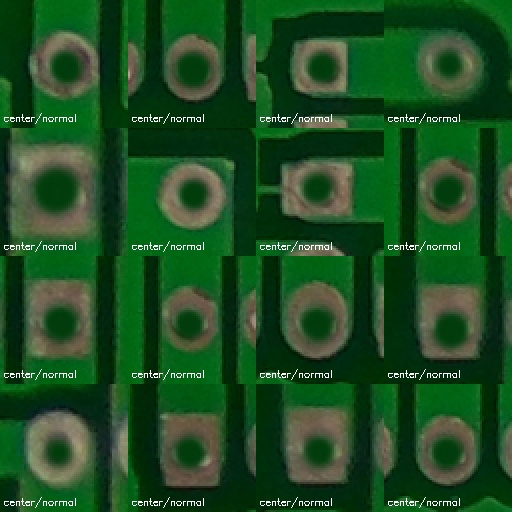

test_mouse_bite.jpg


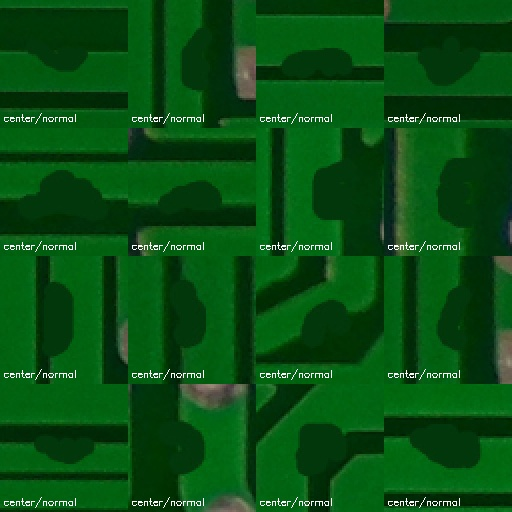

test_normal.jpg


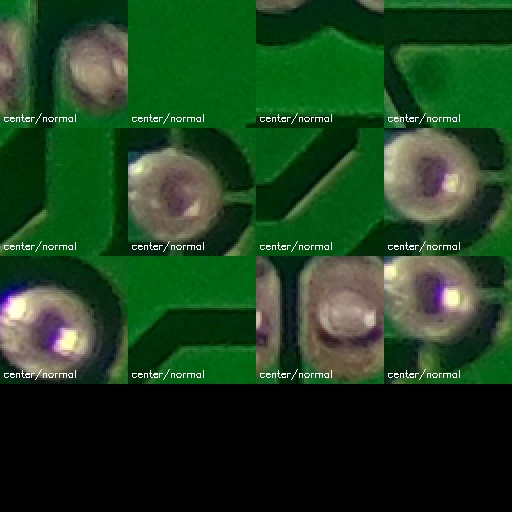

test_open_circuit.jpg


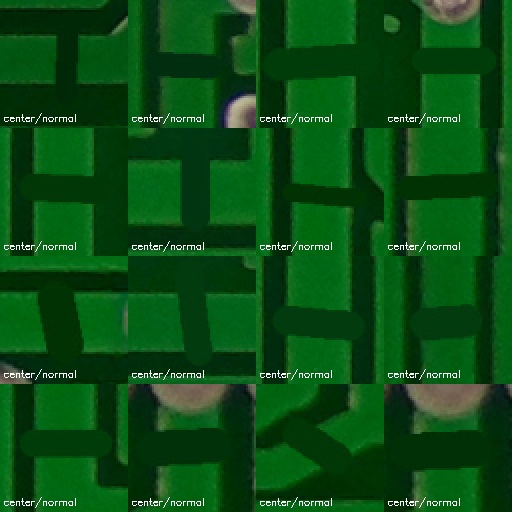

test_short.jpg


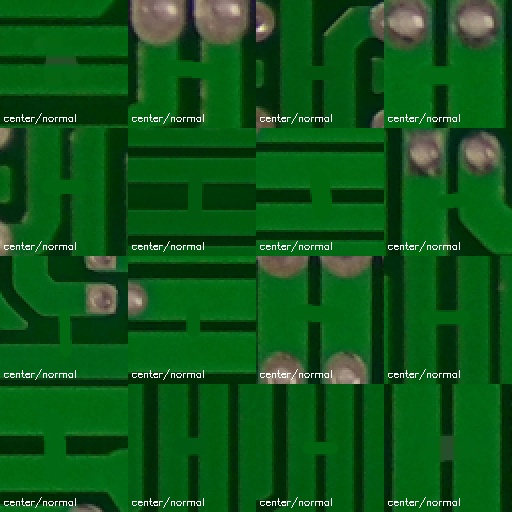

test_spur.jpg


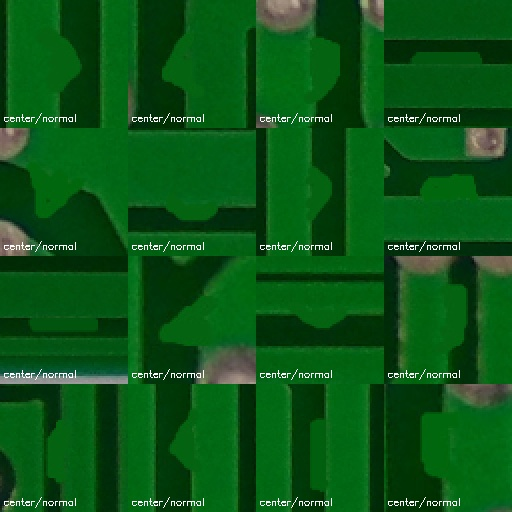

Duyệt các sheet còn lại trước khi train; ảnh Kaggle chỉ là dữ liệu cho lần train thử.


In [ ]:
from pcb_pipeline.data import prepare
DATA_DIR = PROJECT_ROOT / 'dataset_64'
PATCHES_CSV = DATA_DIR / 'patches.csv'
prepare(str(SOURCE_CSV), str(DATA_DIR), size=64, train_copies=3, normal_per_image=12, seed=42)
from IPython.display import display, Image
qa_examples = sorted((DATA_DIR / 'qa_contact_sheets').glob('*.jpg'))
print('QA sheets:', len(qa_examples), '| folder:', DATA_DIR / 'qa_contact_sheets')
for sheet in qa_examples[:6]:
    print(sheet.name)
    display(Image(filename=str(sheet)))
print('Duyệt các sheet còn lại trước khi train; ảnh Kaggle chỉ là dữ liệu cho lần train thử.')


## 2. Huấn luyện embedding
Batch mặc định là 7 lớp × 4 patch = 28 ảnh. Model dùng head 7 logits với cross-entropy và triplet loss; đầu ra anomaly về sau là embedding 32D, không phải softmax. Nếu GPU báo OOM, đổi K_PER_CLASS thành 2.

In [ ]:
from pcb_pipeline.train import train
RUN_DIR = PROJECT_ROOT / 'run_mobilenetv2'
K_PER_CLASS = 4
if (PROJECT_ROOT / 'dataset_64' / 'patches.csv').exists():
    train(str(PATCHES_CSV), str(RUN_DIR), size=64, cut='block_9_add', alpha=0.35,
          emb_dim=32, k=K_PER_CLASS, seed=42, head_epochs=15, tune_epochs=15,
          steps_per_epoch=50, triplet_weight=0.5, margin=0.3, unfreeze_last=20, patience=5)
else:
    print('Bỏ qua: cần chạy prepare trước.')


/content/pcb_pipeline/train.py:23: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base = tf.keras.applications.MobileNetV2(


2019640/2019640 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Frozen backbone baseline on validation: {'pr_auc': 0.9890568530595198, 'auroc': 0.8235607675906184}
{"phase": "head", "epoch": 1, "loss": 4.602278890609742, "ce": 4.188202834129333, "triplet": 0.828152185678482, "pr_auc": 0.973165787200654, "auroc": 0.6901208244491827}
{"phase": "head", "epoch": 2, "loss": 2.464196047782898, "ce": 2.053938398361206, "triplet": 0.8205153226852417, "pr_auc": 0.9739527001481372, "auroc": 0.6977611940298507}
{"phase": "head", "epoch": 3, "loss": 1.9037534999847412, "ce": 1.501476218700409, "triplet": 0.8045545315742493, "pr_auc": 0.9752404742718577, "auroc": 0.7064676616915423}
{"phase": "head", "epoch": 4, "loss": 1.607515902519226, "ce": 1.2202079951763154, "triplet": 0.774615820646286, "pr_auc": 0.9758376958489932, "auroc": 0.7086886993603411}
{"phase": "head", "epoch": 5, "loss": 1.489043447971344, "ce": 1.1122908222675323, "triplet": 0.7535052478313446, "pr_auc": 0.9764461133233711, "auroc": 0.711886993

## Kiểm tra embedding trên validation
So baseline ImageNet với checkpoint tốt nhất và in phân bố điểm normal/lỗi trên board validation. Đây là chẩn đoán cho lần train 1, không phải ngưỡng triển khai.

In [ ]:
import json, numpy as np
from pcb_pipeline.data import read_patches
from pcb_pipeline.train import (load_trained, select_reference_and_validation,
                                embeddings, fit_gaussian, mahalanobis)
rows = read_patches(PATCHES_CSV)
_, reference_rows, validation_rows = select_reference_and_validation(rows)
cfg, _, extractor = load_trained(RUN_DIR)
mean, inv_cov = fit_gaussian(embeddings(extractor, reference_rows, cfg['size']))
scores = mahalanobis(embeddings(extractor, validation_rows, cfg['size']), mean, inv_cov)
normal_scores = scores[[r['class_name'] == 'normal' for r in validation_rows]]
defect_scores = scores[[r['class_name'] != 'normal' for r in validation_rows]]
baseline = json.loads((RUN_DIR / 'baseline_val.json').read_text())
history = json.loads((RUN_DIR / 'history.json').read_text())
diagnostics = {
    'baseline_val_pr_auc': baseline['pr_auc'],
    'best_val_pr_auc': max(record['pr_auc'] for record in history),
    'normal_p50_p90_p99': [float(np.percentile(normal_scores, q)) for q in (50, 90, 99)],
    'defect_p10_p50_p90': [float(np.percentile(defect_scores, q)) for q in (10, 50, 90)],
    'normal_val_patches': int(len(normal_scores)),
    'defect_val_patches': int(len(defect_scores)),
}
(RUN_DIR / 'embedding_diagnostics.json').write_text(json.dumps(diagnostics, indent=2))
print(json.dumps(diagnostics, indent=2))


{
  "baseline_val_pr_auc": 0.9890568530595198,
  "best_val_pr_auc": 0.993576756151715,
  "normal_p50_p90_p99": [
    4.422826766967773,
    5.909130573272705,
    6.448872089385986
  ],
  "defect_p10_p50_p90": [
    5.153028964996338,
    6.475825786590576,
    8.642491340637207
  ],
  "normal_val_patches": 24,
  "defect_val_patches": 469
}


## Lưu kết quả train lần 1 lên Drive
Cell này chỉ lưu checkpoint, cấu hình, lịch sử và manifest để kiểm tra/tái tạo. `patches.csv` chứa đường dẫn `/content` tạm; muốn train lại từ đầu, chạy lại các cell tải Kaggle và `prepare`.

In [ ]:
from datetime import datetime
from shutil import copy2, copytree
TRAIN_DRIVE_DIR = Path('/content/drive/MyDrive/pcb_train_1') / datetime.now().strftime('run_%Y%m%d_%H%M%S_%f')
if not (RUN_DIR / 'best.weights.h5').is_file():
    raise FileNotFoundError('Train chưa tạo best.weights.h5; xem lỗi ở cell train trước khi lưu.')
TRAIN_DRIVE_DIR.mkdir(parents=True, exist_ok=False)
files_to_save = {
    RUN_DIR / 'best.weights.h5': 'best.weights.h5',
    RUN_DIR / 'config.json': 'config.json',
    RUN_DIR / 'baseline_val.json': 'baseline_val.json',
    RUN_DIR / 'history.json': 'history.json',
    RUN_DIR / 'embedding_diagnostics.json': 'embedding_diagnostics.json',
    SOURCE_CSV: 'sources.csv',
    PATCHES_CSV: 'patches.csv',
    DATA_DIR / 'prepare_summary.json': 'prepare_summary.json',
}
for source, name in files_to_save.items():
    if not source.is_file():
        raise FileNotFoundError(source)
    copy2(source, TRAIN_DRIVE_DIR / name)
copytree(DATA_DIR / 'qa_contact_sheets', TRAIN_DRIVE_DIR / 'qa_contact_sheets')
copy2(PACKAGE_DIR / 'data.py', TRAIN_DRIVE_DIR / 'data.py')
copy2(PACKAGE_DIR / 'train.py', TRAIN_DRIVE_DIR / 'train.py')
print('Saved train-1 results to:', TRAIN_DRIVE_DIR)
print('Checkpoint size (MB):', round((TRAIN_DRIVE_DIR / 'best.weights.h5').stat().st_size / 1024**2, 2))


Saved train-1 results to: /content/drive/MyDrive/pcb_train_1/run_20261010_043554_693031
Checkpoint size (MB): 0.44


Số patch val: 493
Accuracy 7 lớp: 79.31%
                 precision    recall  f1-score   support

         normal       0.88      0.96      0.92        24
   open_circuit       0.82      0.81      0.82        80
          short       0.88      0.81      0.84        80
     mouse_bite       0.81      0.55      0.66        78
           spur       0.60      0.72      0.65        74
spurious_copper       0.70      0.83      0.76        81
   missing_hole       0.97      0.99      0.98        76

       accuracy                           0.79       493
      macro avg       0.81      0.81      0.80       493
   weighted avg       0.80      0.79      0.79       493



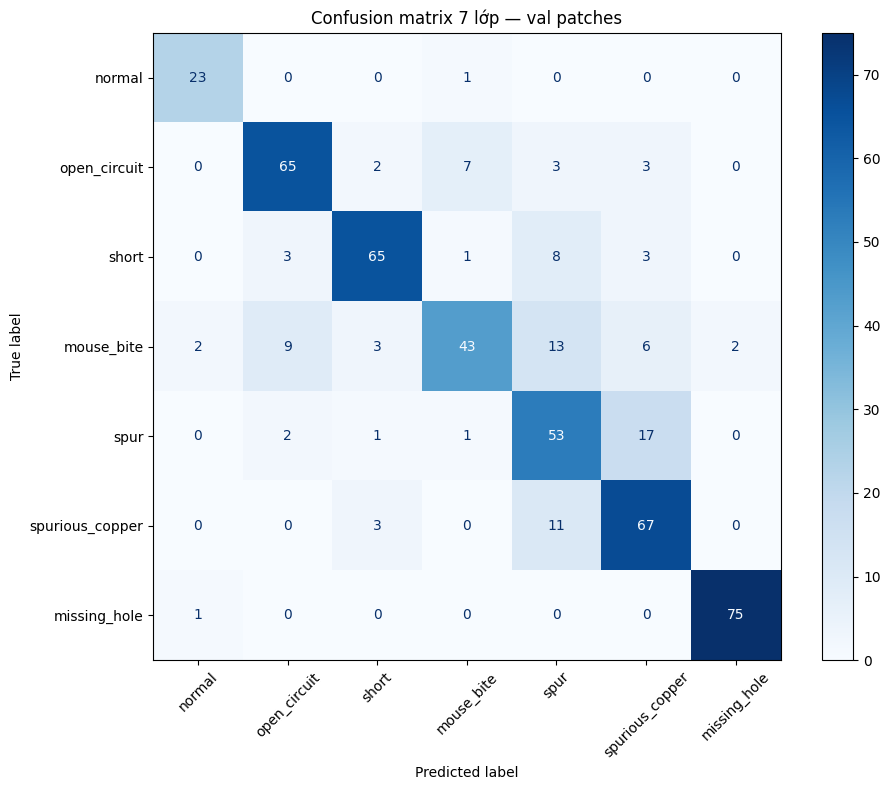

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

from pcb_pipeline.data import CLASS_NAMES, read_patches
from pcb_pipeline.train import load_rgb, load_trained

# Đổi thành "val" nếu muốn xem trước khi chốt model.
SPLIT = "val"
BATCH_SIZE = 64

rows = [r for r in read_patches(PATCHES_CSV) if r["split"] == SPLIT]
if not rows:
    raise ValueError(f"Không có patch trong tập {SPLIT}")

config, model, _ = load_trained(RUN_DIR)
y_true = np.array([int(r["label"]) for r in rows])
y_pred = []

for start in range(0, len(rows), BATCH_SIZE):
    batch = rows[start:start + BATCH_SIZE]
    images = np.stack(
        [load_rgb(r["path"], config["size"]) for r in batch]
    ).astype(np.float32)

    logits, _ = model(images, training=False)
    y_pred.extend(np.argmax(logits.numpy(), axis=1))

y_pred = np.array(y_pred)
labels = list(range(len(CLASS_NAMES)))

print(f"Số patch {SPLIT}: {len(rows)}")
print(f"Accuracy 7 lớp: {accuracy_score(y_true, y_pred):.2%}")
print(classification_report(
    y_true, y_pred,
    labels=labels,
    target_names=CLASS_NAMES,
    zero_division=0,
))

cm = confusion_matrix(y_true, y_pred, labels=labels)
fig, ax = plt.subplots(figsize=(10, 8))
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=CLASS_NAMES,
).plot(ax=ax, cmap="Blues", values_format="d", xticks_rotation=45)
ax.set_title(f"Confusion matrix 7 lớp — {SPLIT} patches")
plt.tight_layout()
plt.show()

In [ ]:
# DÁN TOÀN BỘ CELL NÀY SAU CELL TRAIN TRONG pcb_train_1_colab (2).ipynb.
# Trước đó chạy các cell tạo /content/pcb_pipeline/train.py.

from pathlib import Path
import csv, json, random
import cv2
import numpy as np
import tensorflow as tf
from pcb_pipeline.train import build_models

# Đổi RUN_DIR nếu lần train của bạn lưu ở thư mục khác.
RUN_DIR = Path('/content/drive/MyDrive/pcb_train_1/run_20261010_023923_630857')
# Theo ảnh Colab của bạn: checkpoint nằm trong /content/pcb_project/run_mobilenetv2.
# Đây là thư mục tạm của phiên Colab hiện tại, nên chạy cell trong cùng phiên train.
RUN_DIR = Path('/content/pcb_project/run_mobilenetv2')
WEIGHTS = RUN_DIR / 'best.weights.h5'
CONFIG = RUN_DIR / 'config.json'
OUT_DIR = Path('/content/drive/MyDrive/pcb_train_1/int8_export')

# Ưu tiên ảnh 640x480 chụp thật từ webcam. Nếu chưa có, cell dùng patch
# train Kaggle như bản thử kỹ thuật; sau này PHẢI hiệu chuẩn lại với ảnh thật.
REAL_FRAME_DIR = Path('/content/drive/MyDrive/pcb_camera_calibration')
TRAIN_PATCHES_CSV = Path('/content/pcb_project/dataset_64/patches.csv')
MAX_CALIB_PATCHES = 400
random.seed(42)

if not WEIGHTS.is_file() or not CONFIG.is_file():
    raise FileNotFoundError('Thiếu best.weights.h5 hoặc config.json của lần train mới')
cfg = json.loads(CONFIG.read_text(encoding='utf-8'))
OUT_DIR.mkdir(parents=True, exist_ok=True)

frame_paths = []
if REAL_FRAME_DIR.is_dir():
    frame_paths = sorted(
        p for p in REAL_FRAME_DIR.rglob('*')
        if p.suffix.lower() in {'.jpg', '.jpeg', '.png', '.bmp'}
    )

if frame_paths:
    # Firmware hiện chia 640x480 thành 16x12 patch 40x40.
    candidates = [(p, x, y) for p in frame_paths
                  for y in range(0, 480, 40) for x in range(0, 640, 40)]
    selected = random.sample(candidates, min(MAX_CALIB_PATCHES, len(candidates)))
    calib_source = f'{len(frame_paths)} frame webcam thật, {len(selected)} patch'

    def raw_patches():
        for path, x, y in selected:
            bgr = cv2.imread(str(path), cv2.IMREAD_COLOR)
            if bgr is None or bgr.shape[:2] != (480, 640):
                raise ValueError(f'Frame phải là 640x480: {path}')
            yield cv2.cvtColor(bgr[y:y+40, x:x+40], cv2.COLOR_BGR2RGB)
else:
    if not TRAIN_PATCHES_CSV.is_file():
        raise FileNotFoundError(
            'Chưa có ảnh webcam thật và cũng không tìm thấy patches.csv. '
            'Hãy chạy cell prepare hoặc đặt frame 640x480 trong REAL_FRAME_DIR.'
        )
    with TRAIN_PATCHES_CSV.open(newline='', encoding='utf-8') as f:
        paths = [Path(row['path']) for row in csv.DictReader(f)
                 if row['split'] == 'train']
    if not paths:
        raise ValueError('Không có train patch để hiệu chuẩn')
    selected = random.sample(paths, min(MAX_CALIB_PATCHES, len(paths)))
    calib_source = f'{len(selected)} Kaggle train patch — CHỈ THỬ KỸ THUẬT'

    def raw_patches():
        for path in selected:
            bgr = cv2.imread(str(path), cv2.IMREAD_COLOR)
            if bgr is None:
                raise ValueError(f'Không đọc được {path}')
            yield cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)

raw = list(raw_patches())
if len(raw) < 50:
    raise ValueError('Cần ít nhất 50 patch hiệu chuẩn; nên dùng vài trăm patch')
print('Nguồn hiệu chuẩn:', calib_source)

for target_size in (64, 40):
    # 64: đúng kích thước đã train. 40: dùng lưới patch ESP hiện tại,
    # nhưng phải đánh giá lại vì model được train ở 64.
    model, extractor, _, _ = build_models(
        size=target_size,
        cut=cfg['cut'],
        alpha=float(cfg['alpha']),
        emb_dim=int(cfg['emb_dim']),
        weights=None,
    )
    model.load_weights(WEIGHTS)

    calibration = []
    for image in raw:
        if image.shape[:2] != (target_size, target_size):
            interpolation = cv2.INTER_AREA if image.shape[0] > target_size else cv2.INTER_LINEAR
            image = cv2.resize(image, (target_size, target_size), interpolation=interpolation)
        # Model mới có Rescaling(1/127.5, offset=-1) BÊN TRONG.
        # Representative data phải là RGB float32 0..255; KHÔNG chia 255.
        calibration.append(image.astype(np.float32)[None, ...])

    def representative_dataset():
        for sample in calibration:
            yield [sample]

    for output_dtype, suffix in [(tf.float32, 'i8in_f32out'),
                                 (tf.int8, 'i8in_i8out')]:
        converter = tf.lite.TFLiteConverter.from_keras_model(extractor)
        converter.optimizations = [tf.lite.Optimize.DEFAULT]
        converter.representative_dataset = representative_dataset
        converter.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
        converter.inference_input_type = tf.int8
        converter.inference_output_type = output_dtype
        tflite_bytes = converter.convert()

        output_path = OUT_DIR / f'pcb_embedding_{target_size}_{suffix}.tflite'
        output_path.write_bytes(tflite_bytes)
        interpreter = tf.lite.Interpreter(model_content=tflite_bytes)
        inp = interpreter.get_input_details()[0]
        out = interpreter.get_output_details()[0]
        report = {
            'checkpoint': str(WEIGHTS),
            'calibration': calib_source,
            'input_size': target_size,
            'trained_input_size': int(cfg['size']),
            'file': str(output_path),
            'bytes': len(tflite_bytes),
            'input_dtype': str(inp['dtype']),
            'input_shape': inp['shape'].tolist(),
            'input_scale_zero_point': [float(inp['quantization'][0]),
                                       int(inp['quantization'][1])],
            'output_dtype': str(out['dtype']),
            'output_shape': out['shape'].tolist(),
            'output_scale_zero_point': [float(out['quantization'][0]),
                                        int(out['quantization'][1])],
        }
        report_path = output_path.with_suffix('.json')
        report_path.write_text(json.dumps(report, indent=2, ensure_ascii=False),
                               encoding='utf-8')
        print(json.dumps(report, indent=2, ensure_ascii=False))

print('Đã xuất TFLite vào:', OUT_DIR)

Nguồn hiệu chuẩn: 400 Kaggle train patch — CHỈ THỬ KỸ THUẬT
Saved artifact at '/tmp/tmpx1h0xzq3'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 64, 64, 3), dtype=tf.float32, name='pixels_0_255')
Output Type:
  TensorSpec(shape=(None, 32), dtype=tf.float32, name=None)
Captures:
  133881379417616: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133881379413776: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133881379417808: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133881379417424: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133881379420688: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133881379413392: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133881193427408: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133881193424720: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133881379418768: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133881193425488: TensorSp

/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/convert.py:846: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


{
  "checkpoint": "/content/pcb_project/run_mobilenetv2/best.weights.h5",
  "calibration": "400 Kaggle train patch — CHỈ THỬ KỸ THUẬT",
  "input_size": 64,
  "trained_input_size": 64,
  "file": "/content/drive/MyDrive/pcb_train_1/int8_export/pcb_embedding_64_i8in_f32out.tflite",
  "bytes": 131008,
  "input_dtype": "<class 'numpy.int8'>",
  "input_shape": [
    1,
    64,
    64,
    3
  ],
  "input_scale_zero_point": [
    1.0,
    -128
  ],
  "output_dtype": "<class 'numpy.float32'>",
  "output_shape": [
    1,
    32
  ],
  "output_scale_zero_point": [
    0.0,
    0
  ]
}
Saved artifact at '/tmp/tmp_rp24tz1'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 64, 64, 3), dtype=tf.float32, name='pixels_0_255')
Output Type:
  TensorSpec(shape=(None, 32), dtype=tf.float32, name=None)
Captures:
  133881379417616: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133881379413776: TensorSpec(shape=(), dtype=tf.resource, name=N

/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/convert.py:846: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


{
  "checkpoint": "/content/pcb_project/run_mobilenetv2/best.weights.h5",
  "calibration": "400 Kaggle train patch — CHỈ THỬ KỸ THUẬT",
  "input_size": 64,
  "trained_input_size": 64,
  "file": "/content/drive/MyDrive/pcb_train_1/int8_export/pcb_embedding_64_i8in_i8out.tflite",
  "bytes": 130824,
  "input_dtype": "<class 'numpy.int8'>",
  "input_shape": [
    1,
    64,
    64,
    3
  ],
  "input_scale_zero_point": [
    1.0,
    -128
  ],
  "output_dtype": "<class 'numpy.int8'>",
  "output_shape": [
    1,
    32
  ],
  "output_scale_zero_point": [
    0.2511894702911377,
    13
  ]
}
Saved artifact at '/tmp/tmprd9oo5m2'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 40, 40, 3), dtype=tf.float32, name='pixels_0_255')
Output Type:
  TensorSpec(shape=(None, 32), dtype=tf.float32, name=None)
Captures:
  133878207408528: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133878695766032: TensorSpec(shape=(), dtype=tf.reso

/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/convert.py:846: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


{
  "checkpoint": "/content/pcb_project/run_mobilenetv2/best.weights.h5",
  "calibration": "400 Kaggle train patch — CHỈ THỬ KỸ THUẬT",
  "input_size": 40,
  "trained_input_size": 64,
  "file": "/content/drive/MyDrive/pcb_train_1/int8_export/pcb_embedding_40_i8in_f32out.tflite",
  "bytes": 131088,
  "input_dtype": "<class 'numpy.int8'>",
  "input_shape": [
    1,
    40,
    40,
    3
  ],
  "input_scale_zero_point": [
    1.0,
    -128
  ],
  "output_dtype": "<class 'numpy.float32'>",
  "output_shape": [
    1,
    32
  ],
  "output_scale_zero_point": [
    0.0,
    0
  ]
}
Saved artifact at '/tmp/tmpgeyi6jgc'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 40, 40, 3), dtype=tf.float32, name='pixels_0_255')
Output Type:
  TensorSpec(shape=(None, 32), dtype=tf.float32, name=None)
Captures:
  133878207408528: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133878695766032: TensorSpec(shape=(), dtype=tf.resource, name=N

/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/convert.py:846: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


{
  "checkpoint": "/content/pcb_project/run_mobilenetv2/best.weights.h5",
  "calibration": "400 Kaggle train patch — CHỈ THỬ KỸ THUẬT",
  "input_size": 40,
  "trained_input_size": 64,
  "file": "/content/drive/MyDrive/pcb_train_1/int8_export/pcb_embedding_40_i8in_i8out.tflite",
  "bytes": 130904,
  "input_dtype": "<class 'numpy.int8'>",
  "input_shape": [
    1,
    40,
    40,
    3
  ],
  "input_scale_zero_point": [
    1.0,
    -128
  ],
  "output_dtype": "<class 'numpy.int8'>",
  "output_shape": [
    1,
    32
  ],
  "output_scale_zero_point": [
    0.20840933918952942,
    1
  ]
}
Đã xuất TFLite vào: /content/drive/MyDrive/pcb_train_1/int8_export
